# YOLOv8 Pruning + QAT Pipeline

Full pipeline on Google Colab:

1. **Sparsity training** — L1 regularization on BN gamma
2. **Structured pruning** — Remove channels based on BN gamma threshold
3. **Finetune** — Recovery training on pruned model
4. **QAT** — Quantization-Aware Training (INT8 fake quantization)
5. **Export** — ONNX with Q/DQ nodes → TensorRT INT8 engine

## 0. Setup Environment

In [3]:
import os, sys, shutil, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
print(f"Colab: {IN_COLAB}")
print(f"Python: {sys.version.split()[0]}")

import torch
print(f"Torch: {torch.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
assert torch.cuda.is_available(), "GPU required!"

Colab: True
Python: 3.12.13
Torch: 2.10.0+cu128
CUDA: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [4]:
# Mount Google Drive (dataset stored here)
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# Clone repo
REPO_URL = "https://github.com/NguyenTienAnh8365/Deploying-QAT-for-YOLOv8-on-waste-detection-tasks-for-edge-devices.git"
BRANCH = "pruned-QAT"
CLONE_DIR = Path("/content/yolov8-pruned-QAT")

if IN_COLAB:
    if CLONE_DIR.exists():
        shutil.rmtree(CLONE_DIR)
    !git clone -b {BRANCH} --single-branch {REPO_URL} {CLONE_DIR}

    if (CLONE_DIR / "prune.py").exists():
    if (CLONE_DIR / "prune.py").exists():
    if (CLONE_DIR / "prune.py").exists():
    if (CLONE_DIR / "prune.py").exists():
    if (CLONE_DIR / "prune.py").exists():
    if (CLONE_DIR / "prune.py").exists():
    if (CLONE_DIR / "scripts/prune.py").exists():
    if (CLONE_DIR / "prune.py").exists():
    if (CLONE_DIR / "prune.py").exists():
    if (CLONE_DIR / "prune.py").exists():
    if (CLONE_DIR / "prune.py").exists():
    if (CLONE_DIR / "prune.py").exists():
    if (CLONE_DIR / "prune.py").exists():
        REPO = CLONE_DIR
    elif (CLONE_DIR / "yolov8-pruned-QAT" / "prune.py").exists():
        REPO = CLONE_DIR / "yolov8-pruned-QAT"
    else:
        hits = list(CLONE_DIR.rglob("prune.py"))
        hits = list(CLONE_DIR.rglob("prune.py"))
        hits = list(CLONE_DIR.rglob("prune.py"))
        hits = list(CLONE_DIR.rglob("prune.py"))
        hits = list(CLONE_DIR.rglob("prune.py"))
        hits = list(CLONE_DIR.rglob("prune.py"))
        hits = list(CLONE_DIR.rglob("prune.py"))
        hits = list(CLONE_DIR.rglob("prune.py"))
        hits = list(CLONE_DIR.rglob("scripts/prune.py"))
        hits = list(CLONE_DIR.rglob("prune.py"))
        hits = list(CLONE_DIR.rglob("prune.py"))
        hits = list(CLONE_DIR.rglob("prune.py"))
        hits = list(CLONE_DIR.rglob("prune.py"))
        assert hits, f"prune.py not found in {CLONE_DIR}"
        assert hits, f"prune.py not found in {CLONE_DIR}"
        assert hits, f"prune.py not found in {CLONE_DIR}"
        assert hits, f"prune.py not found in {CLONE_DIR}"
        assert hits, f"prune.py not found in {CLONE_DIR}"
        assert hits, f"prune.py not found in {CLONE_DIR}"
        assert hits, f"prune.py not found in {CLONE_DIR}"
        assert hits, f"prune.py not found in {CLONE_DIR}"
        assert hits, f"prune.py not found in {CLONE_DIR}"
        assert hits, f"prune.py not found in {CLONE_DIR}"
        assert hits, f"prune.py not found in {CLONE_DIR}"
        assert hits, f"scripts/prune.py not found in {CLONE_DIR}"
        assert hits, f"prune.py not found in {CLONE_DIR}"
        REPO = hits[0].parent
else:
    REPO = Path.cwd().resolve()
    if not (REPO / "prune.py").exists():
    if not (REPO / "prune.py").exists():
    if not (REPO / "prune.py").exists():
    if not (REPO / "prune.py").exists():
    if not (REPO / "scripts/prune.py").exists():
    if not (REPO / "prune.py").exists():
    if not (REPO / "prune.py").exists():
    if not (REPO / "prune.py").exists():
    if not (REPO / "prune.py").exists():
    if not (REPO / "prune.py").exists():
    if not (REPO / "prune.py").exists():
    if not (REPO / "prune.py").exists():
    if not (REPO / "prune.py").exists():
        REPO = REPO / "yolov8-pruned-QAT"

assert (REPO / "prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "scripts/prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "prune.py").exists(), f"scripts/prune.py not found in {REPO}"
assert (REPO / "prune.py").exists(), f"prune.py not found in {REPO}"
assert (REPO / "qat_pruned.py").exists(), f"qat_pruned.py not found in {REPO}"
assert (REPO / "scripts/qat.py").exists(), f"scripts/qat.py not found in {REPO}"
assert (REPO / "qat_pruned.py").exists(), f"qat_pruned.py not found in {REPO}"
assert (REPO / "qat_pruned.py").exists(), f"qat_pruned.py not found in {REPO}"
assert (REPO / "qat_pruned.py").exists(), f"qat_pruned.py not found in {REPO}"
assert (REPO / "scripts/qat.py").exists(), f"qat_pruned.py not found in {REPO}"
assert (REPO / "qat_pruned.py").exists(), f"qat_pruned.py not found in {REPO}"
assert (REPO / "qat_pruned.py").exists(), f"qat_pruned.py not found in {REPO}"
assert (REPO / "qat_pruned.py").exists(), f"qat_pruned.py not found in {REPO}"
assert (REPO / "qat_pruned.py").exists(), f"qat_pruned.py not found in {REPO}"
assert (REPO / "qat_pruned.py").exists(), f"qat_pruned.py not found in {REPO}"
assert (REPO / "qat_pruned.py").exists(), f"qat_pruned.py not found in {REPO}"
assert (REPO / "qat_pruned.py").exists(), f"qat_pruned.py not found in {REPO}"
print(f"REPO: {REPO}")


Cloning into '/content/yolov8-pruned-QAT'...
remote: Enumerating objects: 59957, done.
remote: Counting objects: 100% (916/916), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 59957 (delta 900), reused 873 (delta 873), pack-reused 59041 (from 1)
Receiving objects: 100% (59957/59957), 29.17 MiB | 53.92 MiB/s, done.
Resolving deltas: 100% (33428/33428), done.
REPO: /content/yolov8-pruned-QAT


In [5]:
# Install dependencies
!cd {REPO} && pip install -e . -q
!pip install nvidia-pyindex -q
!pip install --no-cache-dir pytorch-quantization==2.1.2 --extra-index-url https://pypi.nvidia.com -q
!pip install "numpy<2.0" -q

print("\n⚠️  RESTART RUNTIME NOW: menu → Runtime → Restart session")
print("    Sau khi restart, chạy lại từ cell đầu (SKIP cell install này lần 2)")


  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for ultralytics (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 45.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 158.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-contrib-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
pytensor 2.38.2 requires numpy>=2.0, but you have numpy 1.26.4 which is 

In [1]:
import ultralytics, pytorch_quantization, numpy
print(f"ultralytics:         {ultralytics.__version__}")
print(f"ultralytics path:    {ultralytics.__file__}")   # PHẢI trỏ vào /content/yolov8-pruned-QAT/ultralytics/...
print(f"pytorch_quantization:{pytorch_quantization.__version__}")
print(f"numpy:               {numpy.__version__}")      # phải là 1.26.x


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics:         8.3.231
ultralytics path:    /content/yolov8-pruned-QAT/ultralytics/__init__.py
pytorch_quantization:2.1.2
numpy:               1.26.4


## 1. Config

In [6]:
import yaml
from pathlib import Path

# ── Paths ─────────────────────────────────────────────────────────────
# Dataset: sua lai cho dung path tren Drive cua ban
DATASET_DRIVE = Path("/content/drive/MyDrive/yolov8/dataset")  # <-- SUA NEU CAN
DATASET_LOCAL = Path("/content/dataset")

# Pretrained weight (FP32 best.pt tu fine-tune truoc do)
PRETRAINED_WEIGHT = Path("/content/drive/MyDrive/export_engine/check_point_yolov8s/phase_C.pt")  # <-- SUA NEU CAN

# ── Model ─────────────────────────────────────────────────────────────
NC = 3
CLASS_NAMES = ["PAPER", "PLASTIC", "GLASS"]
MODEL_SIZE = "s"
MODEL_CFG_PATH = REPO / "ultralytics" / "cfg" / "models" / "v8" / "yolov8.yaml"
IMGSZ = 640
DEVICE = 0

# ── Directories ────────────────────────────────────────────────────────
WEIGHTS_DIR = REPO / "weights"
RUNS_DIR = REPO / "runs"
DATA_YAML = REPO / "data.yaml"
DATA_YAML = REPO / "data.yaml"
DATA_YAML = REPO / "data.yaml"
DATA_YAML = REPO / "data.yaml"
DATA_YAML = REPO / "data.yaml"
DATA_YAML = REPO / "data.yaml"
DATA_YAML = REPO / "data.yaml"
DATA_YAML = REPO / "data.yaml"
DATA_YAML = REPO / "data.yaml"
DATA_YAML = REPO / "configs/data.yaml"
DATA_YAML = REPO / "data.yaml"
DATA_YAML = REPO / "data.yaml"
DATA_YAML = REPO / "data.yaml"
WEIGHTS_DIR.mkdir(exist_ok=True)
RUNS_DIR.mkdir(exist_ok=True)

# ── Workers ────────────────────────────────────────────────────────────
WORKERS = 12 if IN_COLAB else 0
CACHE = "ram" if IN_COLAB else "disk"

print(f"REPO:       {REPO}")
print(f"DATASET:    {DATASET_DRIVE}")
print(f"PRETRAINED: {PRETRAINED_WEIGHT}")

REPO:       /content/yolov8-pruned-QAT
DATASET:    /content/drive/MyDrive/yolov8/dataset
PRETRAINED: /content/drive/MyDrive/export_engine/check_point_yolov8s/phase_C.pt


In [ ]:
# Copy dataset to local disk (faster I/O than Drive)
if IN_COLAB:
    assert DATASET_DRIVE.exists(), f"Dataset not found: {DATASET_DRIVE}"
    if DATASET_LOCAL.exists():
        shutil.rmtree(DATASET_LOCAL)
    shutil.copytree(DATASET_DRIVE, DATASET_LOCAL)
    print(f"Copied dataset -> {DATASET_LOCAL}")
else:
    DATASET_LOCAL = DATASET_DRIVE  # local: use directly

# Verify splits
for split in ["train", "val", "test"]:
    img_dir = DATASET_LOCAL / split / "images"
    lbl_dir = DATASET_LOCAL / split / "labels"
    assert img_dir.exists(), f"Missing: {img_dir}"
    assert lbl_dir.exists(), f"Missing: {lbl_dir}"
    print(f"{split:5s}: {len(list(img_dir.glob('*'))):5d} images")

# Write data.yaml
data_cfg = {
    "train": str(DATASET_LOCAL / "train" / "images"),
    "val":   str(DATASET_LOCAL / "val" / "images"),
    "test":  str(DATASET_LOCAL / "test" / "images"),
    "nc": NC,
    "names": CLASS_NAMES,
}
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)
print(f"\nWrote: {DATA_YAML}")
print(DATA_YAML.read_text())

Copied dataset -> /content/dataset
train: 16883 images
val  :  2434 images
test :  2012 images

Wrote: /content/yolov8-pruned-QAT/data.yaml
train: /content/dataset/train/images
val: /content/dataset/val/images
test: /content/dataset/test/images
nc: 3
names:
- PAPER
- PLASTIC
- GLASS



In [7]:
# Write data.yaml
data_cfg = {
    "train": str(DATASET_LOCAL / "train" / "images"),
    "val":   str(DATASET_LOCAL / "val" / "images"),
    "test":  str(DATASET_LOCAL / "test" / "images"),
    "nc": NC,
    "names": CLASS_NAMES,
}
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)
print(f"\nWrote: {DATA_YAML}")
print(DATA_YAML.read_text())


Wrote: /content/yolov8-pruned-QAT/data.yaml
train: /content/dataset/train/images
val: /content/dataset/val/images
test: /content/dataset/test/images
nc: 3
names:
- PAPER
- PLASTIC
- GLASS



In [ ]:
# Copy pretrained weight to repo weights dir
assert PRETRAINED_WEIGHT.exists(), f"Pretrained weight not found: {PRETRAINED_WEIGHT}"
LOCAL_PRETRAINED = WEIGHTS_DIR / "original.pt"
if not LOCAL_PRETRAINED.exists():
    shutil.copy2(PRETRAINED_WEIGHT, LOCAL_PRETRAINED)
print(f"Pretrained: {LOCAL_PRETRAINED} ({LOCAL_PRETRAINED.stat().st_size / 1e6:.1f} MB)")

Pretrained: /content/yolov8-pruned-QAT/weights/original.pt (22.5 MB)


In [8]:
def run(cmd):
    cmd = [str(x) for x in cmd]
    print("$", " ".join(cmd))
    result = subprocess.run(cmd, cwd=str(REPO), capture_output=True, text=True)
    print(result.stdout)
    if result.returncode != 0:
        print("STDERR:", result.stderr)
        raise RuntimeError(f"Command failed with code {result.returncode}")


## 2. Step 1 — Sparsity Training

Train with L1 regularization on BN gamma (`sr` parameter) to push unimportant channels toward zero.

In [9]:
import pytorch_quantization
from pytorch_quantization import nn as quant_nn
x = torch.randn(1,3,640,640).cuda()
conv = quant_nn.QuantConv2d(3, 16, 3).cuda()
print(conv(x).shape)   # nếu in ra được thì OK


torch.Size([1, 16, 638, 638])


In [ ]:
from ultralytics import YOLO

model = YOLO(str(LOCAL_PRETRAINED))
model.train(
    data=str(DATA_YAML),
    epochs=80,
    imgsz=IMGSZ,
    batch=96,
    sr=1.5e-2,
    optimizer="SGD",
    lr0=1e-2,
    lrf=0.01,
    momentum=0.937,
    weight_decay=5e-4,
    warmup_bias_lr=0.05,
    warmup_epochs=3.0,
    patience=50,
    workers=WORKERS,
    cache=CACHE,
    device=DEVICE,
    project=str(RUNS_DIR),
    name="train-sparsity2",
    exist_ok=True,
)

New https://pypi.org/project/ultralytics/8.4.37 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.231 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=96, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolov8-pruned-QAT/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, finetune=None, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/yolov8-pruned-QAT/weights/original.pt,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f9b138666f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [ ]:
SPARSITY_WEIGHT = RUNS_DIR / "train-sparsity2" / "weights" / "last.pt"
assert SPARSITY_WEIGHT.exists(), f"Not found: {SPARSITY_WEIGHT}"
print(f"Step 1 done: {SPARSITY_WEIGHT}")

Step 1 done: /content/yolov8-pruned-QAT/runs/train-sparsity2/weights/last.pt


## 3. Step 2 — Structured Pruning

Remove channels where BN gamma < threshold. Output: `pruned.pt` with `maskbndict`.

In [ ]:
prune_path = REPO / "prune.py"
prune_path = REPO / "prune.py"
prune_path = REPO / "prune.py"
prune_path = REPO / "prune.py"
prune_path = REPO / "scripts/prune.py"
prune_path = REPO / "prune.py"
prune_path = REPO / "prune.py"
prune_path = REPO / "prune.py"
prune_path = REPO / "prune.py"
prune_path = REPO / "prune.py"
prune_path = REPO / "prune.py"
prune_path = REPO / "prune.py"
prune_path = REPO / "prune.py"
src = prune_path.read_text()

# Fix 1: nargs='+' list issue (đã patch lần trước, idempotent)
if "if isinstance(weights, list):" not in src:
    src = src.replace(
        "    model = AutoBackend(weights, fuse=False)",
        "    if isinstance(weights, list):\n"
        "        weights = weights[0]\n"
        "    model = AutoBackend(weights, fuse=False)"
    )

# Fix 2: torch.load weights_only for PyTorch 2.6+
if 'model = torch.load(save_path)["model"]' in src:
    src = src.replace(
        'model = torch.load(save_path)["model"]',
        'model = torch.load(save_path, weights_only=False)["model"]'
    )

prune_path.write_text(src)
print("Patched prune.py")
print("Patched prune.py")
print("Patched prune.py")
print("Patched prune.py")
print("Patched prune.py")
print("Patched prune.py")
print("Patched prune.py")
print("Patched prune.py")
print("Patched prune.py")
print("Patched prune.py")
print("Patched prune.py")
print("Patched prune.py")
print("Patched scripts/prune.py")


Patched prune.py


In [ ]:
PRUNE_RATIO = 0.3

run([
    sys.executable, "prune.py",
    sys.executable, "prune.py",
    sys.executable, "prune.py",
    sys.executable, "prune.py",
    sys.executable, "prune.py",
    sys.executable, "prune.py",
    sys.executable, "prune.py",
    sys.executable, "scripts/prune.py",
    sys.executable, "prune.py",
    sys.executable, "prune.py",
    sys.executable, "prune.py",
    sys.executable, "prune.py",
    sys.executable, "prune.py",
    "--weights", str(SPARSITY_WEIGHT),
    "--cfg", str(MODEL_CFG_PATH),
    "--model-size", MODEL_SIZE,
    "--prune-ratio", str(PRUNE_RATIO),
    "--save-dir", str(WEIGHTS_DIR),
])

$ /usr/bin/python3 prune.py --weights /content/yolov8-pruned-QAT/runs/train-sparsity2/weights/last.pt --cfg /content/yolov8-pruned-QAT/ultralytics/cfg/models/v8/yolov8.yaml --model-size s --prune-ratio 0.3 --save-dir /content/yolov8-pruned-QAT/weights
Pruning gamma values should be less than 0.4880, yours is 0.0002
The corresponding pruing ratio should be less than 0.727, yours is 0.300
|	layer name               |         origin channels     |         remaining channels  |
|	model.0.bn               |         32                  |         18                  |
|	model.1.bn               |         64                  |         58                  |
|	model.2.cv1.bn           |         64                  |         64                  |
|	model.2.cv2.bn           |         64                  |         62                  |
|	model.2.m.0.cv1.bn       |         32                  |         31                  |
|	model.2.m.0.cv2.bn       |         32                  |         32       

In [ ]:
import glob

pruned_files = sorted(glob.glob(str(WEIGHTS_DIR / "pruned*.pt")))
assert pruned_files, f"No pruned weight found in {WEIGHTS_DIR}"
PRUNED_WEIGHT = Path(pruned_files[-1])

ckpt = torch.load(PRUNED_WEIGHT, map_location="cpu", weights_only=False)
assert "maskbndict" in ckpt, "Invalid pruned checkpoint: missing maskbndict"
params = sum(p.numel() for p in ckpt["model"].parameters())
print(f"Step 2 done: {PRUNED_WEIGHT}")
print(f"Pruned params: {params:,}")

Step 2 done: /content/yolov8-pruned-QAT/weights/pruned_05.pt
Pruned params: 6,468,719


## 4. Step 3 — Finetune Pruned Model

Recovery training to restore accuracy after pruning.

In [ ]:
from ultralytics import YOLO

model = YOLO(str(LOCAL_PRETRAINED))
r = model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMGSZ,
    batch=96,
    device=DEVICE,
    workers=WORKERS,
)
print(f"phase_C (FP32 baseline): mAP50={r.box.map50:.4f}, mAP50-95={r.box.map:.4f}")

Ultralytics 8.3.231 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
Model summary (fused): 73 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1668.9±960.7 MB/s, size: 14.6 KB)
val: Scanning /content/dataset/val/labels.cache... 2434 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2434/2434 12.8Mit/s 0.0s
val: /content/dataset/val/images/2c8035ea9adc.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 4.6it/s 5.7s
                   all       2434       3349      0.888      0.842      0.891      0.784
                 PAPER        925       1026      0.938      0.922      0.954      0.881
               PLASTIC        680       1148      0.797      0.727      0.781      0.651
                 GLASS        836       1175       0.93      0.876      0.937      0.822
Speed: 0.2ms preproc

In [ ]:
# Evaluate Finetuned Pruned Model on Validation set
from ultralytics import YOLO

# Load the best weight from finetune step
model_eval = YOLO(str(FINETUNE_WEIGHT))

print(f"Evaluating model: {FINETUNE_WEIGHT}")
results = model_eval.val(
    data=str(DATA_YAML),
    split='val',
    imgsz=IMGSZ,
    batch=16,
    device=DEVICE,
    workers=WORKERS,
    plots=True
)

print(f"\nResults for Pruned + Finetuned Model:")
print(f"mAP50:    {results.box.map50:.4f}")
print(f"mAP50-95: {results.box.map:.4f}")

Evaluating model: /content/yolov8-pruned-QAT/runs/train-finetune/weights/best.pt
Ultralytics 8.3.231 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
Model summary (fused): 72 layers, 6,461,218 parameters, 0 gradients, 17.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1816.0±2229.1 MB/s, size: 18.9 KB)
val: Scanning /content/dataset/val/labels.cache... 2434 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2434/2434 12.0Mit/s 0.0s
val: /content/dataset/val/images/2c8035ea9adc.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 153/153 28.5it/s 5.4s
                   all       2434       3349      0.891       0.82      0.888      0.783
                 PAPER        925       1026      0.939      0.901      0.949      0.879
               PLASTIC        680       1148      0.803      0.711      0.782      0.646
                 GLASS   

In [ ]:
best = RUNS_DIR / "train-finetune" / "weights" / "best.pt"
last = RUNS_DIR / "train-finetune" / "weights" / "last.pt"
FINETUNE_WEIGHT = best if best.exists() else last
assert FINETUNE_WEIGHT.exists(), f"Not found: {FINETUNE_WEIGHT}"
print(f"Step 3 done: {FINETUNE_WEIGHT}")

Step 3 done: /content/yolov8-pruned-QAT/runs/train-finetune/weights/best.pt


## 5. Step 4 — QAT on Pruned Model

Quantization-Aware Training with INT8 fake quantization.

Note: `--lr0 1e-3` → trainer auto-scales to `1e-5` (divides by 100).

In [ ]:
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python scripts/qat.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
!cd /content/yolov8-pruned-QAT && PYTHONUNBUFFERED=1 python qat_pruned.py \
    --pruned-checkpoint {PRUNED_WEIGHT} \
    --pretrained-weight {FINETUNE_WEIGHT} \
    --data-config {DATA_YAML} \
    --epochs 10 --imgsz 640 --batch 16 --device 0 --workers 12 --cache ram \
    --lr0 1e-3 --freeze 10 --optimizer AdamW --patience 5 --recalib-every 1 \
    --project {RUNS_DIR}/qat-pruned --name train --exist-ok --plots


[QAT-Pruned] Pruned checkpoint: /content/yolov8-pruned-QAT/weights/pruned_05.pt
[QAT-Pruned] Finetuned weight: /content/yolov8-pruned-QAT/runs/train-finetune/weights/best.pt
Ultralytics 8.3.231 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=0.04, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=2.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolov8-pruned-QAT/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.2, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, finetune=None, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=

In [ ]:
qat_best = RUNS_DIR / "qat-pruned" / "train" / "weights" / "best.pt"
qat_last = RUNS_DIR / "qat-pruned" / "train" / "weights" / "last.pt"
QAT_WEIGHT = qat_best if qat_best.exists() else qat_last
assert QAT_WEIGHT.exists(), f"Not found: {QAT_WEIGHT}"
print(f"Step 4 done: {QAT_WEIGHT}")

Step 4 done: /content/yolov8-pruned-QAT/runs/qat-pruned/train/weights/best.pt


In [ ]:
import torch
from pathlib import Path
from ultralytics import YOLO

# Load + tắt fuse
ckpt_path = Path("/content/yolov8-pruned-QAT/runs/qat-pruned/train/weights/best.pt")
model = torch.load(ckpt_path, map_location='cpu', weights_only=False)
ema = model.get('ema') or model.get('model')
ema.fuse = lambda *a, **k: ema  # no-op fuse
ema.eval().cuda()

# Val bằng DetectionValidator trực tiếp
from ultralytics.models.yolo.detect.val import DetectionValidator
from ultralytics.cfg import get_cfg
args = get_cfg(overrides=dict(
    data="/content/yolov8-pruned-QAT/data.yaml",
    data="/content/yolov8-pruned-QAT/data.yaml",
    data="/content/yolov8-pruned-QAT/data.yaml",
    data="/content/yolov8-pruned-QAT/data.yaml",
    data="/content/yolov8-pruned-QAT/data.yaml",
    data="/content/yolov8-pruned-QAT/data.yaml",
    data="/content/yolov8-pruned-QAT/data.yaml",
    data="/content/yolov8-pruned-QAT/data.yaml",
    data="/content/yolov8-pruned-QAT/data.yaml",
    data="/content/yolov8-pruned-QAT/data.yaml",
    data="/content/yolov8-pruned-QAT/configs/data.yaml",
    data="/content/yolov8-pruned-QAT/data.yaml",
    data="/content/yolov8-pruned-QAT/data.yaml",
    imgsz=640, batch=32, device=0, plots=False, save_json=False,
))
validator = DetectionValidator(args=args)
validator(model=ema)


Ultralytics 8.3.231 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3692.6±2550.2 MB/s, size: 44.8 KB)
val: Scanning /content/dataset/val/labels.cache... 2434 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2434/2434 13.3Mit/s 0.0s
val: /content/dataset/val/images/2c8035ea9adc.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 77/77 13.1it/s 5.9s
                   all       2434       3349      0.859      0.802       0.87      0.765
                 PAPER        925       1026      0.907      0.882      0.941      0.869
               PLASTIC        680       1148      0.762      0.678       0.75      0.622
                 GLASS        836       1175      0.908      0.845      0.919      0.803
Speed: 0.2ms preprocess, 1.5ms inference, 0.0ms loss, 0.2ms postprocess per image


{'metrics/precision(B)': 0.8590433201044201,
 'metrics/recall(B)': 0.801925930271257,
 'metrics/mAP50(B)': 0.8699262384466729,
 'metrics/mAP50-95(B)': 0.7645512236211481,
 'fitness': 0.7645512236211481}

## 6. Step 5 — Export ONNX + TensorRT Engine

Export ONNX with Q/DQ nodes. Build `.engine` if `trtexec` is available.

In [10]:
# Install missing dependency and run export
!pip install onnxscript -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 130.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.1/164.1 kB 17.4 MB/s eta 0:00:00


In [9]:
%cd /content/yolov8-pruned-QAT

/content/yolov8-pruned-QAT


In [11]:
!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_r0.30.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"!python -c "from ultralytics.qat.nvidia_tensorrt.qat_pruned_exporter import export_onnx_pruned; export_onnx_pruned(pruned_checkpoint='/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/pruned_05.pt', qat_weight='/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.pt')"


                   from  n    params  module                                            arguments                     
  0                  -1  1       522  ultralytics.nn.modules.conv.Conv                  [3, 18, 3, 2]                 
  1                  -1  1      9512  ultralytics.nn.modules.conv.Conv                  [18, 58, 3, 2]                
  2                  -1  1     27898  ultralytics.nn.modules.block_pruned.C2fPruned     [58, 64, [32, 32], [31], [32], 62, 1, True]
  3                  -1  1     66080  ultralytics.nn.modules.conv.Conv                  [62, 118, 3, 2]               
  4                  -1  2    188654  ultralytics.nn.modules.block_pruned.C2fPruned     [118, 128, [64, 64], [60, 62], [64, 64], 125, 2, True]
  5                  -1  1    233289  ultralytics.nn.modules.conv.Conv                  [125, 207, 3, 2]              
  6                  -1  2    730802  ultralytics.nn.modules.block_pruned.C2fPruned     [207, 256, [128, 128], [116, 126], [128, 

In [11]:
!pip install -q tensorrt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.7 MB/s eta 0:00:00


In [2]:
%cd /content/yolov8-pruned-QAT


/content/yolov8-pruned-QAT


In [4]:
# Rebuild engine
!python build_engine.py \
!python build_engine.py \
!python scripts/build_engine.py \
!python build_engine.py \
!python build_engine.py \
!python build_engine.py \
!python build_engine.py \
!python build_engine.py \
!python build_engine.py \
!python build_engine.py \
!python build_engine.py \
!python build_engine.py \
!python build_engine.py \
    --onnx /content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.tensorrt.onnx \
    --engine /content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.engine \
    --nc 3 --names '{"0":"PAPER","1":"PLASTIC","2":"GLASS"}'

[04/15/2026-04:44:48] [TRT] [I] [MemUsageChange] Init CUDA: CPU +38, GPU +0, now: CPU 50, GPU 558 (MiB)
[04/15/2026-04:44:48] [TRT] [I] ----------------------------------------------------------------
[04/15/2026-04:44:48] [TRT] [I] ONNX IR version:  0.0.7
[04/15/2026-04:44:48] [TRT] [I] Opset version:    13
[04/15/2026-04:44:48] [TRT] [I] Producer name:    pytorch
[04/15/2026-04:44:48] [TRT] [I] Producer version: 2.10.0
[04/15/2026-04:44:48] [TRT] [I] Domain:           
[04/15/2026-04:44:48] [TRT] [I] Model version:    0
[04/15/2026-04:44:48] [TRT] [I] Doc string:       
[04/15/2026-04:44:48] [TRT] [I] ----------------------------------------------------------------
[build] FP16 enabled
[build] INT8 enabled (scales từ QAT QDQ nodes)
[build] TensorRT 10.16.1.11 — đang build engine, có thể mất vài phút...
[04/15/2026-04:44:49] [TRT] [I] [MemUsageChange] Init builder kernel library: CPU +286, GPU +4, now: CPU 563, GPU 564 (MiB)
[04/15/2026-04:44:49] [TRT] [W] /model.0/conv/_input_quantiz

### 7. Performance Comparison (PyTorch vs TensorRT)
Compare accuracy (mAP), speed (FPS), and Latency (ms).

In [5]:
import yaml
from pathlib import Path

# Đường dẫn dataset trực tiếp trên Drive theo yêu cầu
DRIVE_DATASET_BASE = Path('/content/drive/MyDrive/yolov8/dataset')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/configs/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')
NEW_DATA_YAML = Path('/content/yolov8-pruned-QAT/data.yaml')

# Cấu hình data.yaml
data_config = {
    'train': str(DRIVE_DATASET_BASE / 'train' / 'images'),
    'val':   str(DRIVE_DATASET_BASE / 'val' / 'images'),
    'test':  str(DRIVE_DATASET_BASE / 'test' / 'images'),
    'nc': 3,
    'names': ['PAPER', 'PLASTIC', 'GLASS']
}

# Ghi file
with open(NEW_DATA_YAML, 'w') as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print(f'Đã tạo file YAML mới tại: {NEW_DATA_YAML}')
print('Nội dung file:')
print(NEW_DATA_YAML.read_text())

Đã tạo file YAML mới tại: /content/yolov8-pruned-QAT/data.yaml
Nội dung file:
train: /content/drive/MyDrive/yolov8/dataset/train/images
val: /content/drive/MyDrive/yolov8/dataset/val/images
test: /content/drive/MyDrive/yolov8/dataset/test/images
nc: 3
names:
- PAPER
- PLASTIC
- GLASS



In [22]:
import time
import numpy as np
import torch
from ultralytics import YOLO

IMGSZ = 640
DEVICE = 0

DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/configs/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
DATA_YAML = '/content/yolov8-pruned-QAT/data.yaml'
ORIGINAL_PT = '/content/drive/MyDrive/yolov8-pruned-QAT-backup/weights/original.pt'
FINETUNE_PT = '/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/train-finetune/weights/best.pt'
TRT_ENGINE = '/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.engine'

def benchmark_model(model_path, label):
    print(f'\n--- Testing {label} ---')
    model = YOLO(model_path)

    # Patch fuse for PyTorch .pt: prevents automatic BN+Conv fusion which can break QAT patterns
    if model_path.endswith('.pt'):
        model.model.fuse = lambda verbose=True: model.model

    # Set workers=0 to avoid multiprocessing errors in Colab
    results = model.val(data=str(DATA_YAML), imgsz=IMGSZ, batch=1,
                        device=DEVICE, plots=False, verbose=False, workers=0)
    map50 = results.box.map50
    map50_95 = results.box.map

    # Warmup
    for _ in range(10):
        model.predict(torch.zeros((1, 3, IMGSZ, IMGSZ)), device=DEVICE, verbose=False)

    latencies = []
    for _ in range(100):
        start = time.perf_counter()
        model.predict(torch.zeros((1, 3, IMGSZ, IMGSZ)), device=DEVICE, verbose=False)
        latencies.append((time.perf_counter() - start) * 1000)

    avg_latency = float(np.mean(latencies))
    fps = 1000 / avg_latency

    print(f'Accuracy: mAP50={map50:.4f}, mAP50-95={map50_95:.4f}')
    print(f'Latency:  {avg_latency:.2f} ms')
    print(f'FPS:      {fps:.2f}')
    return {'label': label, 'mAP50': map50, 'mAP50-95': map50_95, 'latency': avg_latency, 'fps': fps}

# Run benchmarks
stats_orig = benchmark_model(ORIGINAL_PT, 'Original FP32')
stats_fine = benchmark_model(FINETUNE_PT, 'Pruned Finetuned FP32')
stats_trt  = benchmark_model(TRT_ENGINE, 'TensorRT INT8 Engine')

# Summary Table
print('\n' + '=' * 80)
print(f"{'Model':<25} | {'mAP50':<8} | {'Latency (ms)':<12} | {'FPS':<8}")
print('-' * 80)
for s in [stats_orig, stats_fine, stats_trt]:
    print(f"{s['label']:<25} | {s['mAP50']:<8.4f} | {s['latency']:<12.2f} | {s['fps']:<8.2f}")
print('=' * 80)

speedup = stats_orig['latency'] / stats_trt['latency']
print(f'Speedup: TensorRT INT8 is {speedup:.2f}x faster than Original FP32')



--- Testing Original FP32 ---
Ultralytics 8.3.231 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
val: Fast image access ✅ (ping: 0.2±0.1 ms, read: 62.7±74.8 MB/s, size: 28.4 KB)
val: Scanning /content/drive/MyDrive/yolov8/dataset/val/labels.cache... 2434 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2434/2434 9.1Mit/s 0.0s
val: WARNING ⚠️ /content/drive/MyDrive/yolov8/dataset/val/images/2c8035ea9adc.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2434/2434 170.3it/s 14.3s
                   all       2434       3349      0.885      0.844       0.89      0.784
Speed: 0.1ms preprocess, 2.6ms inference, 0.0ms loss, 0.4ms postprocess per image
Accuracy: mAP50=0.8901, mAP50-95=0.7837
Latency:  3.21 ms
FPS:      311.29

--- Testing Pruned Finetuned FP32 ---
Ultralytics 8.3.231 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Bl

### 8. Visual Inference Test
Compare the detection results of the PyTorch (.pt) and TensorRT (.engine) models on custom test images.

WARNING ⚠️ Unable to automatically guess model task, assuming 'task=detect'. Explicitly define task for your model, i.e. 'task=detect', 'segment', 'classify','pose' or 'obb'.
Starting visualization with high-precision timing (averaging 10 runs)...
Loading /content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.engine for TensorRT inference...


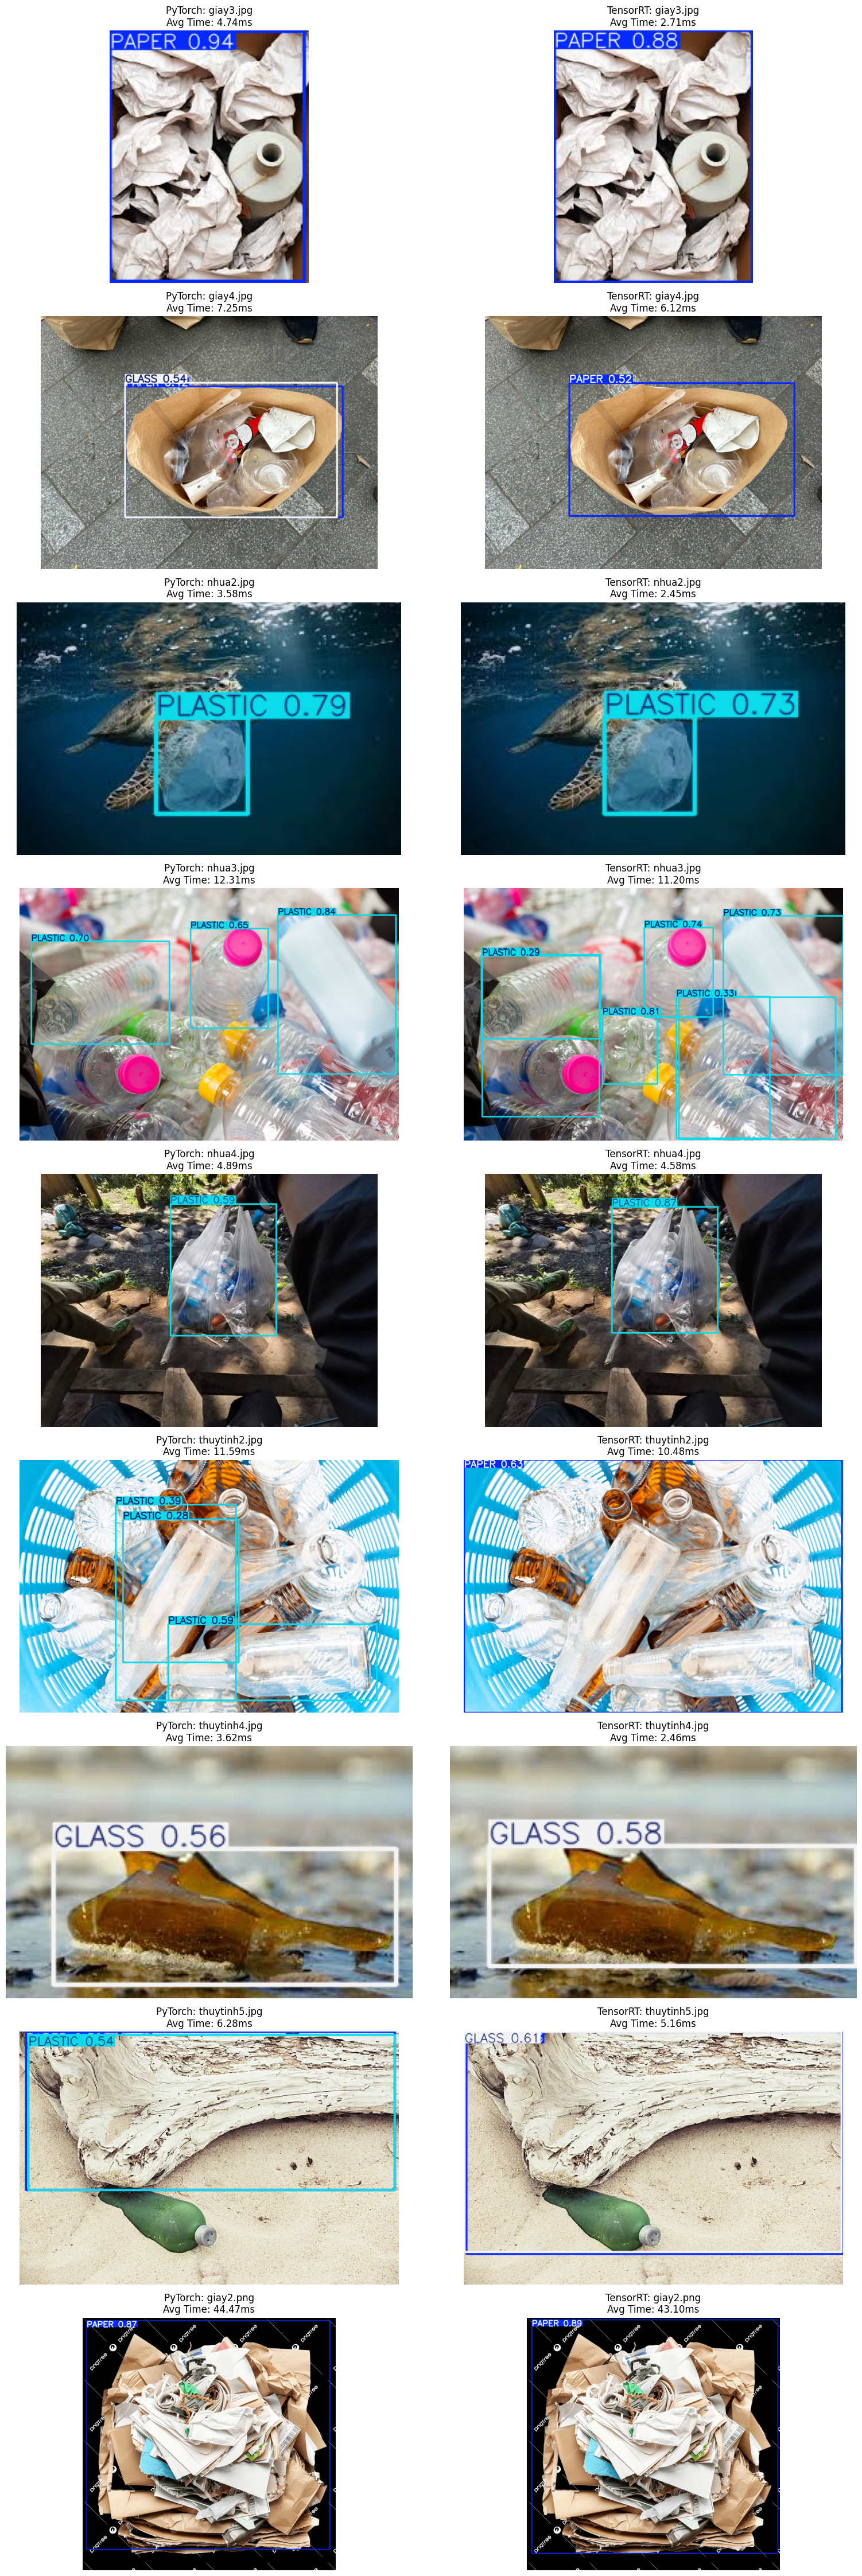

In [17]:
import cv2
import time
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

# Configuration
N_REPEAT = 10
IMGSZ = 640
DEVICE = 0

# Paths
TEST_IMG_DIR = Path('/content/drive/MyDrive/Pruned-QAT/test_imgs')
PT_PATH = '/content/drive/MyDrive/Pruned-QAT/phase_C.pt'
TRT_PATH = '/content/drive/MyDrive/yolov8-pruned-QAT-backup/runs/qat-pruned/train/weights/best.engine'

# Load models
model_pt = YOLO(PT_PATH)
model_trt = YOLO(TRT_PATH)

# Get images from directory
img_paths = sorted(list(TEST_IMG_DIR.glob('*.jpg'))) + sorted(list(TEST_IMG_DIR.glob('*.png')))

if not img_paths:
    print(f"No images found in {TEST_IMG_DIR}")
else:
    fig, axes = plt.subplots(len(img_paths), 2, figsize=(16, 5 * len(img_paths)))
    if len(img_paths) == 1:
        axes = axes.reshape(1, 2)

    print(f"Starting visualization with high-precision timing (averaging {N_REPEAT} runs)...")
    for i, img_p in enumerate(img_paths):
        img_str = str(img_p)

        # --- PyTorch Accurate Timing ---
        model_pt.predict(img_str, imgsz=IMGSZ, device=DEVICE, verbose=False) # Warmup
        t_pt_list = []
        for _ in range(N_REPEAT):
            t1 = time.perf_counter()
            res_pt = model_pt.predict(img_str, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
            t_pt_list.append((time.perf_counter() - t1) * 1000)
        dt_pt = np.mean(t_pt_list)
        plot_pt = cv2.cvtColor(res_pt.plot(), cv2.COLOR_BGR2RGB)

        # --- TensorRT Accurate Timing ---
        model_trt.predict(img_str, imgsz=IMGSZ, device=DEVICE, verbose=False) # Warmup
        t_trt_list = []
        for _ in range(N_REPEAT):
            t2 = time.perf_counter()
            res_trt = model_trt.predict(img_str, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
            t_trt_list.append((time.perf_counter() - t2) * 1000)
        dt_trt = np.mean(t_trt_list)
        plot_trt = cv2.cvtColor(res_trt.plot(), cv2.COLOR_BGR2RGB)

        # Plotting results
        axes[i, 0].imshow(plot_pt)
        axes[i, 0].set_title(f"PyTorch: {img_p.name}\nAvg Time: {dt_pt:.2f}ms")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(plot_trt)
        axes[i, 1].set_title(f"TensorRT: {img_p.name}\nAvg Time: {dt_trt:.2f}ms")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

In [18]:
import pandas as pd
import numpy as np

results_list = []
N_REPEAT = 10  # Number of iterations to average

print(f"Calculating accurate benchmark (averaging {N_REPEAT} runs per image)...")

for img_p in img_paths:
    # --- PyTorch Benchmark ---
    # Warmup
    model_pt.predict(str(img_p), imgsz=640, device=0, verbose=False)

    t_pt_list = []
    for _ in range(N_REPEAT):
        t1 = time.perf_counter()
        model_pt.predict(str(img_p), imgsz=640, device=0, verbose=False)
        t_pt_list.append((time.perf_counter() - t1) * 1000)
    dt_pt = np.mean(t_pt_list)

    # --- TensorRT Benchmark ---
    # Warmup
    model_trt.predict(str(img_p), imgsz=640, device=0, verbose=False)

    t_trt_list = []
    for _ in range(N_REPEAT):
        t2 = time.perf_counter()
        model_trt.predict(str(img_p), imgsz=640, device=0, verbose=False)
        t_trt_list.append((time.perf_counter() - t2) * 1000)
    dt_trt = np.mean(t_trt_list)

    results_list.append({
        'Image': img_p.name,
        'PyTorch (ms)': round(float(dt_pt), 2),
        'TensorRT (ms)': round(float(dt_trt), 2),
        'Speedup (x)': round(float(dt_pt / dt_trt), 2)
    })

df_comparison = pd.DataFrame(results_list)
display(df_comparison)

# Summary stats
print(f"\nGlobal Average Speedup: {df_comparison['Speedup (x)'].mean():.2f}x")

Calculating accurate benchmark (averaging 10 runs per image)...


,Image,PyTorch (ms),TensorRT (ms),Speedup (x)
0,giay3.jpg,4.60,2.81,1.64
1,giay4.jpg,7.40,6.27,1.18
2,nhua2.jpg,3.77,2.66,1.42
3,nhua3.jpg,12.43,11.40,1.09
4,nhua4.jpg,5.04,4.87,1.03
5,thuytinh2.jpg,11.75,10.69,1.10
6,thuytinh4.jpg,3.80,2.63,1.45
7,thuytinh5.jpg,6.43,5.33,1.21
8,giay2.png,44.67,43.04,1.04



Global Average Speedup: 1.24x


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/yolov8-pruned-QAT-backup
!rsync -av --exclude='datasets' --exclude='__pycache__' --exclude='*.cache' \
    /content/yolov8-pruned-QAT/ /content/drive/MyDrive/yolov8-pruned-QAT-backup/


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
sending incremental file list
./
.dockerignore
.gitignore
data.yaml
export.py
finetune.py
prune.py
pyproject.toml
qat_pruned.py
qat_pruned_export.py
run_pruning_qat.ipynb
train-normal.py
train-sparsity.py
train.py
val.py
vis-bn-weight.py
.git/
.git/HEAD
.git/config
.git/description
.git/index
.git/packed-refs
.git/branches/
.git/hooks/
.git/hooks/applypatch-msg.sample
.git/hooks/commit-msg.sample
.git/hooks/fsmonitor-watchman.sample
.git/hooks/post-update.sample
.git/hooks/pre-applypatch.sample
.git/hooks/pre-commit.sample
.git/hooks/pre-merge-commit.sample
.git/hooks/pre-push.sample
.git/hooks/pre-rebase.sample
.git/hooks/pre-receive.sample
.git/hooks/prepare-commit-msg.sample
.git/hooks/push-to-checkout.sample
.git/hooks/update.sample
.git/info/
.git/info/exclude
.git/logs/
.git/logs/HEAD
.git/logs/refs/
.git/logs/refs/heads/
.git/logs/refs/heads/pruned-QAT